# judge 프롬프트와 편향

**이 노트북에서 할 일**

1. 02절 근거 충실도 판정 머리글을 다시 적고 한 문장을 더한 새 판을 만듭니다.
2. 두 판으로 평가 모델(judge)에게 세 사례의 판정을 받아 점수를 나란히 봅니다.
3. 두 글 가운데 하나를 고르게 하는 쌍 비교 머리글을 만듭니다.
4. 같은 두 글의 차례만 바꿔 두 번 묻고 판정이 자리 쪽으로 치우치는지(편향) 봅니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 여덟 번이고 임베딩 요청은 없습니다.
머리글 두 판으로 세 사례를 판정하는 데 6번, 차례를 바꾼 쌍 비교에 2번입니다.
예상 비용은 미화 0.05달러 아래이고 실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 하나이고 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 8초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~6절을 읽습니다.
머리글에 한 문장을 더하고 판 이름을 바꿔 두 판의 점수를 견주는 자리입니다.
7~8절은 쌍 비교 머리글을 만들고 치우친 판정의 모습을 보는 자리입니다.
9절은 값 바꿔 보기이고 실습 시간에 함께 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위쪽에 칸 둘이 나란히 있고 아래에 회색 상자 하나가 있는 그림으로 왼쪽 칸 머리글만 바꾸기에는 초록 상자 사례 세 건의 두 칸 답 근거 문서에서 파란 상자 근거 충실도 머리글 두 판 rag-judge-v1.0.0 v1.1.0을 지나 노란 상자 질문 번호별 점수 두 판을 나란히로 이어지고 오른쪽 칸 차례만 바꾸기에는 초록 상자 같은 두 답 짧은 답 긴 답에서 파란 상자 쌍 비교 두 차례 짧은 답 먼저 긴 답 먼저를 지나 노란 상자 두 차례에서 고른 글 이름으로 이어지며 맨 아래 회색 상자에 두 실험 모두 같은 평가 모델 gpt-5.4-mini 바꾼 것 하나 말고 나머지는 그대로가 적힌 그림](attachment:03-1-한-번에-하나만-바꾸기.png)

위쪽 두 칸이 이 절의 두 실험입니다.
왼쪽 칸은 머리글만 바꾸고 오른쪽 칸은 두 글의 차례만 바꿉니다.
칸마다 초록 상자가 넣은 값, 파란 상자가 바꾼 한 가지, 노란 상자가 견줄 출력입니다.
맨 아래 회색 상자는 두 칸에 모두 해당합니다.
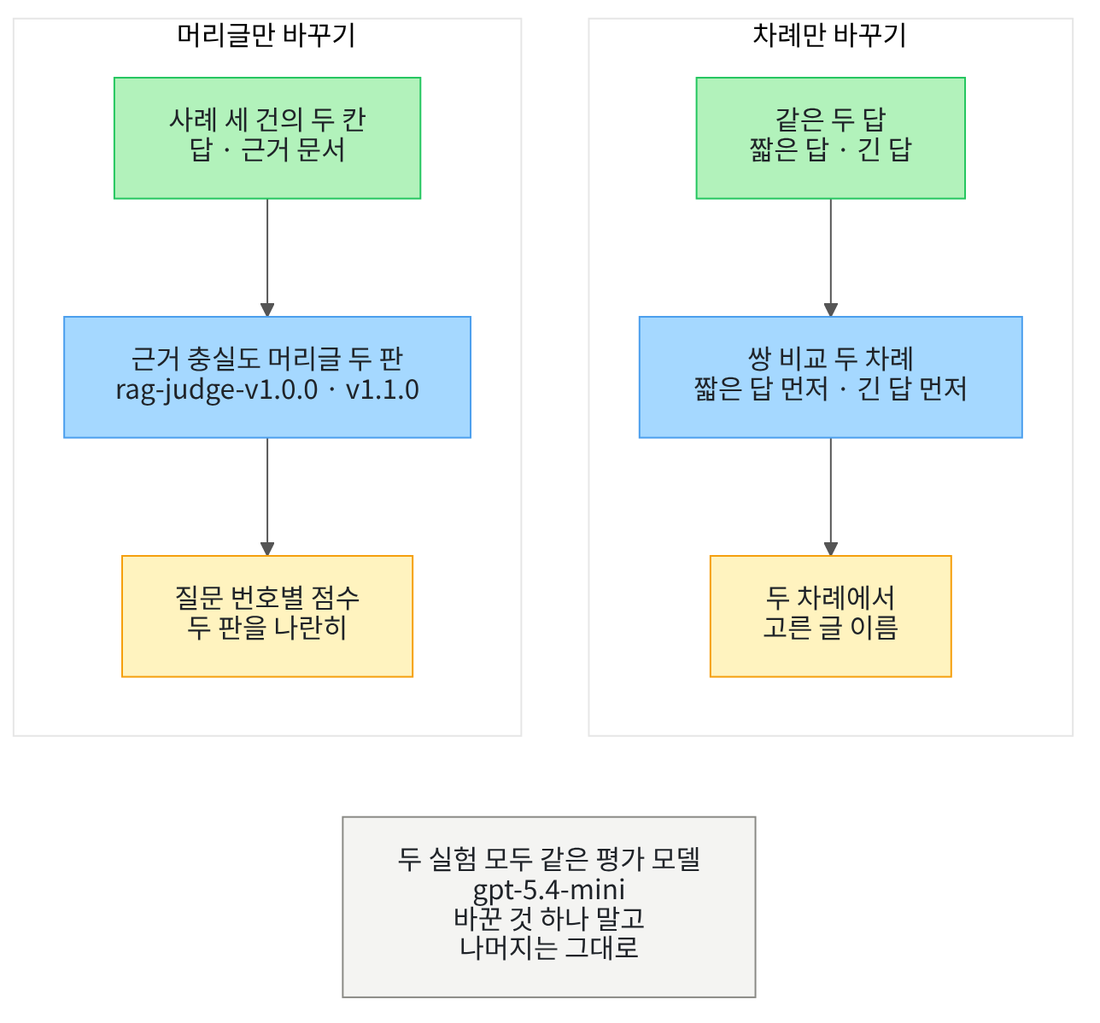

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 불러오고 02절 함수 둘을 도구 파일에서 가져옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `build_judge_prompt()`와 `judge_once()`를 가져옵니다.
두 함수 모두 02절에서 쓰던 인자 그대로입니다.

In [2]:
# 자료 읽기·폴더 확인·지문 계산에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import hashlib
import json
import os

from langchain.chat_models import init_chat_model

# Ch 15 02절에서 배운 함수 둘을 도구 파일에서 가져옵니다
from rag_tools import build_judge_prompt, judge_once

print("불러온 이름:", "hashlib", "json", "os", "init_chat_model")

불러온 이름: hashlib json os init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
이름 `hashlib`은 Ch 7 08절에서 쓴 것이고 글의 지문을 만듭니다.
도구 파일에서 가져온 함수 둘은 출력하지 않습니다.

## 2. 키와 모델 준비

이 절도 02절과 같은 평가 모델 `gpt-5.4-mini`를 부릅니다.
모델을 만드는 설정 값도 02절과 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 평가 사례와 02절 판정 머리글

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01·02절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 02절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.

In [6]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록과 질문 번호 목록을 만듭니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("평가 사례의 질문 번호:", case_qids)

평가 사례 수: 3
평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']`도 02절과 같습니다.

02절은 평가 넷마다 판정 머리글을 썼습니다.
이 절은 그 가운데 근거 충실도 하나만 골라 머리글을 바꿔 봅니다.
02절에서 사례 Q090이 0점을 받은 평가입니다.
다음 셀은 02절의 두 칸 짝과 기준 문장과 출력 모양을 그대로 다시 적습니다.

In [7]:
# 02절 근거 충실도의 두 칸 짝과 기준 문장과 출력 모양을 그대로 다시 적습니다
ground_pair = {"답": "response", "근거 문서": "context"}
ground_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_heads = {}
judge_heads["rag-judge-v1.0.0"] = ground_rule + "\n" + output_rule
pair_labels = list(ground_pair.keys())
print("근거 충실도 두 칸:", pair_labels)
print("rag-judge-v1.0.0 판정 머리글:")
print(judge_heads["rag-judge-v1.0.0"])

근거 충실도 두 칸: ['답', '근거 문서']
rag-judge-v1.0.0 판정 머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `근거 충실도 두 칸: ['답', '근거 문서']`는 02절과 같은 두 칸입니다.
라벨 줄 `rag-judge-v1.0.0 판정 머리글:` 아래 두 줄은 02절 근거 충실도 머리글과 글자까지 같습니다.
이번에는 판 이름을 딕셔너리 `judge_heads`의 키로 삼았습니다.
02절에서는 같은 이름의 딕셔너리가 평가 이름을 키로 삼았습니다.
머리글이 여러 판이 되어도 판 이름으로 꺼낼 수 있습니다.

## 4. 머리글에 한 문장 더하기

02절 기준 문장은 모른다고 답한 경우를 어떻게 셀지 적지 않았습니다.
사례 Q090은 답과 기준 답이 모두 「확인할 수 없다」는 글입니다.
그래서 기준 문장 뒤에 그 경우를 세는 문장 하나를 더합니다.
머리글이 바뀌므로 판 이름도 새로 붙입니다.

In [8]:
# 기준 문장 뒤에 모른다고 답한 경우를 세는 문장 하나를 더해 새 판을 만듭니다
unknown_rule = "근거 문서에 없는 정보를 없다고 답하면 뒷받침된 것으로 보세요."
new_rule = ground_rule + " " + unknown_rule
judge_heads["rag-judge-v1.1.0"] = new_rule + "\n" + output_rule
print("rag-judge-v1.1.0 판정 머리글:")
print(judge_heads["rag-judge-v1.1.0"])
version_names = list(judge_heads.keys())
print("판 이름 목록:", version_names)

rag-judge-v1.1.0 판정 머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요. 근거 문서에 없는 정보를 없다고 답하면 뒷받침된 것으로 보세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.
판 이름 목록: ['rag-judge-v1.0.0', 'rag-judge-v1.1.0']


**결과 읽기** — 라벨 줄 `rag-judge-v1.1.0 판정 머리글:` 아래 첫 줄 끝에 더한 문장이 붙었습니다.
둘째 줄 출력 모양은 두 판이 같습니다.
출력 줄 `판 이름 목록: ['rag-judge-v1.0.0', 'rag-judge-v1.1.0']`으로 두 판을 모두 담았습니다.

더한 문장은 판정을 받아 보기 전에 정했습니다.
다음 셀은 사례 Q090의 요청 글을 두 판으로 만들어 글자 수를 견줍니다.

In [9]:
# 사례 Q090의 근거 충실도 요청 글을 두 판으로 만들어 글자 수를 견줍니다(모델을 부르지 않습니다)
last_case = cases[2]
print("판 이름 | 요청 글자 수")
for version in judge_heads:
    prompt_text = build_judge_prompt(judge_heads[version], ground_pair, last_case)
    print(version, "|", len(prompt_text))
print("더한 문장 글자 수:", len(unknown_rule))

판 이름 | 요청 글자 수
rag-judge-v1.0.0 | 5093
rag-judge-v1.1.0 | 5129
더한 문장 글자 수: 35


**결과 읽기** — 라벨 줄 `판 이름 | 요청 글자 수` 아래 두 줄이 두 판의 요청 글 길이입니다.
출력 줄 `rag-judge-v1.0.0 | 5093`과 `rag-judge-v1.1.0 | 5129`는 36자 차이입니다.
출력 줄 `더한 문장 글자 수: 35`에 띄어쓰기 한 칸을 더한 만큼입니다.

두 요청 글에서 답과 근거 문서 부분은 같은 글입니다.
머리글만 바꾸고 나머지는 그대로 두었습니다.
그래야 판정이 달라졌을 때 까닭을 머리글에서 찾을 수 있습니다.

다음 셀은 두 판의 판정 조건을 한 줄씩 적습니다.
지문은 글에서 계산한 64글자짜리 표시로 Ch 7 08절에서 파일을 견줄 때 썼습니다.

In [10]:
# 판 이름마다 판정 조건을 한 줄로 적고 머리글 지문을 만듭니다(hashlib은 Ch 7 08절에서 쓴 이름입니다)
print("판 이름 | 모델 | temperature | 머리글 지문 앞 여덟 글자")
for version in judge_heads:
    head_bytes = judge_heads[version].encode("utf-8")
    head_hash = hashlib.sha256(head_bytes)
    fingerprint = head_hash.hexdigest()
    print(version, "|", model.model_name, "|", model.temperature, "|", fingerprint[:8])

판 이름 | 모델 | temperature | 머리글 지문 앞 여덟 글자
rag-judge-v1.0.0 | gpt-5.4-mini | 0.0 | ede6f64d
rag-judge-v1.1.0 | gpt-5.4-mini | 0.0 | a802a7f8


**결과 읽기** — 라벨 줄 `판 이름 | 모델 | temperature | 머리글 지문 앞 여덟 글자` 아래 두 줄이 판정 조건입니다.
두 줄 모두 `gpt-5.4-mini | 0.0`으로 모델과 temperature가 같습니다.
머리글 지문 앞 여덟 글자는 두 줄이 서로 다릅니다.

지문은 글이 한 글자만 달라도 바뀝니다.
판 이름은 사람이 붙이므로 머리글을 고치고 이름을 그대로 두는 실수가 생길 수 있습니다.
판정을 적어 둘 때 판 이름과 지문을 함께 적으면 그런 실수를 알아챌 수 있습니다.

## 5. 두 판으로 판정 받기

다음 셀은 머리글 하나로 사례 여러 건의 판정을 받는 함수입니다.
02절 `judge_case()`는 사례 한 건에 평가 넷을 걸었습니다.
이번에는 평가 하나를 사례 여러 건에 겁니다.

In [11]:
# 판정 머리글 하나로 사례 여러 건의 판정을 받아 질문 번호별로 모읍니다(사례 한 건에 모델 요청 1번)
def score_cases(judge_model, judge_head, pair, case_list):
    verdicts = {}
    for case in case_list:
        prompt_text = build_judge_prompt(judge_head, pair, case)
        verdicts[case["qid"]] = judge_once(judge_model, prompt_text)
    return verdicts

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `score_cases`는 평가 모델과 판정 머리글과 두 칸 짝과 사례 목록을 받습니다.
사례마다 `build_judge_prompt()`로 요청 글을 만들고 `judge_once()`로 판정을 받습니다.
판정은 질문 번호를 키로 삼은 딕셔너리에 모입니다.

다음 셀은 02절 판으로 세 사례의 판정을 받습니다.
02절에서 받은 판정을 이 노트북에서 한 번 더 받는 것입니다.
두 판을 같은 실행에서 받아야 머리글 말고 다른 조건이 섞이지 않습니다.

In [12]:
# 02절 판 rag-judge-v1.0.0으로 세 사례의 근거 충실도 판정을 받습니다(모델 요청 3번)
old_verdicts = score_cases(model, judge_heads["rag-judge-v1.0.0"], ground_pair, cases)
print("질문 번호 | 점수 | 까닭")
for qid in old_verdicts:
    verdict = old_verdicts[qid]
    print(qid, "|", verdict["score"], "|", verdict["reason"])

질문 번호 | 점수 | 까닭
Q002 | 1 | 근거 문서 4항에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.
Q006 | 1 | 근거 문서에 회원은 주차장을 최초 2시간 무료로 이용하고 이후 30분마다 500원이라고 명시되어 있습니다.
Q090 | 0 | 근거 문서에는 ‘입회인’에 대한 언급이 없으므로 답변의 내용이 문서로 뒷받침되지 않습니다.


**결과 읽기** — 라벨 줄 `질문 번호 | 점수 | 까닭` 아래 세 줄이 02절 판의 판정입니다.
이 셀에서 모델 요청이 세 번 나갔습니다.

이번 실행에서 점수는 `Q002`와 `Q006`이 1, `Q090`이 0이었습니다.
02절에서 받은 근거 충실도 점수와 같습니다.
사례 Q090 까닭은 근거 문서에 입회인 언급이 없다는 점을 짚었습니다.
까닭 글은 모델이 쓴 문장이라 실행마다 달라질 수 있습니다.

다음 셀은 한 문장을 더한 판으로 같은 세 사례의 판정을 받습니다.

In [13]:
# 한 문장을 더한 판 rag-judge-v1.1.0으로 같은 세 사례의 판정을 받습니다(모델 요청 3번)
new_verdicts = score_cases(model, judge_heads["rag-judge-v1.1.0"], ground_pair, cases)
print("질문 번호 | 점수 | 까닭")
for qid in new_verdicts:
    verdict = new_verdicts[qid]
    print(qid, "|", verdict["score"], "|", verdict["reason"])

질문 번호 | 점수 | 까닭
Q002 | 1 | 근거 문서에 도서는 한 번에 7권까지, 대출 기간은 14일이라고 명시되어 있습니다.
Q006 | 1 | 근거 문서에 주차장은 회원이 최초 2시간 무료이고 이후 30분마다 500원이라고 명시되어 있습니다.
Q090 | 1 | 근거 문서에는 ‘입회인’에 대한 별도 기재가 없으므로 알 수 없다는 답변은 문서 내용에 부합합니다.


**결과 읽기** — 라벨 줄 `질문 번호 | 점수 | 까닭` 아래 세 줄이 새 판의 판정입니다.
이 셀에서도 모델 요청이 세 번 나갔습니다.

이번 실행에서 점수는 세 사례 모두 1이었습니다.
사례 Q090 까닭은 문서에 입회인 기재가 없으니 알 수 없다는 답이 문서에 맞는다고 적었습니다.
까닭 글은 실행마다 달라질 수 있습니다.

## 6. 두 판의 점수 견주기

다음 셀은 두 판의 점수를 질문 번호마다 나란히 놓습니다.
점수가 달라진 사례도 따로 모읍니다.

In [14]:
# 두 판의 점수를 질문 번호마다 나란히 놓고 점수가 달라진 사례를 모읍니다
changed_qids = []
print("질문 번호 | rag-judge-v1.0.0 | rag-judge-v1.1.0")
for qid in case_qids:
    old_score = old_verdicts[qid]["score"]
    new_score = new_verdicts[qid]["score"]
    print(qid, "|", old_score, "|", new_score)
    if old_score != new_score:
        changed_qids.append(qid)
print("점수가 달라진 사례:", changed_qids)

질문 번호 | rag-judge-v1.0.0 | rag-judge-v1.1.0
Q002 | 1 | 1
Q006 | 1 | 1
Q090 | 0 | 1
점수가 달라진 사례: ['Q090']


**결과 읽기** — 라벨 줄 `질문 번호 | rag-judge-v1.0.0 | rag-judge-v1.1.0` 아래 세 줄이 두 판의 점수입니다.
가운데가 02절 판이고 오른쪽이 한 문장을 더한 판입니다.
출력 줄 `점수가 달라진 사례:` 뒤에 두 판의 점수가 다른 질문 번호가 모입니다.

이번 실행에서 `Q002`와 `Q006`은 두 판 모두 1이었습니다.
사례 Q090만 `Q090 | 0 | 1`로 점수가 달라졌습니다.
두 판 사이에 바꾼 것은 머리글의 문장 하나뿐입니다.
같은 답인데 머리글에 문장 하나를 더하자 판정이 0에서 1로 바뀌었습니다.
같은 요청 글이어도 실행한 때에 따라 판정이 달라질 수 있습니다.

이 결과는 이번에 본 사례 세 건의 결과입니다.
머리글이 판정을 바꿀 수 있다는 것을 보여 줄 뿐이고 어느 판이 맞는지는 정하지 않습니다.
교재 작성자가 판정 전에 적은 제시 라벨과 견주는 일은 04절에서 합니다.

다음 셀은 사례 Q090의 답과 두 판의 까닭을 나란히 봅니다.

In [15]:
# 사례 Q090의 답과 두 판의 까닭을 나란히 출력합니다
print("답:", last_case["response"])
print("rag-judge-v1.0.0 까닭:", old_verdicts["Q090"]["reason"])
print("rag-judge-v1.1.0 까닭:", new_verdicts["Q090"]["reason"])

답: 제공된 근거에는 “입회인”이 누구인지에 대한 내용이 별도로 기재되어 있지 않아 알 수 없습니다. [H01]
rag-judge-v1.0.0 까닭: 근거 문서에는 ‘입회인’에 대한 언급이 없으므로 답변의 내용이 문서로 뒷받침되지 않습니다.
rag-judge-v1.1.0 까닭: 근거 문서에는 ‘입회인’에 대한 별도 기재가 없으므로 알 수 없다는 답변은 문서 내용에 부합합니다.


**결과 읽기** — 출력 줄 `답:`은 자료 파일에 적힌 사례 Q090의 답입니다.
그 아래 두 줄이 두 판의 까닭입니다.

이번 실행에서 02절 판의 까닭은 문서에 입회인 언급이 없어 답을 뒷받침하지 못한다고 적었습니다.
새 판의 까닭은 입회인 기재가 없으니 알 수 없다는 답이 문서 내용에 맞는다고 적었습니다.
두 까닭 모두 문서에 입회인 기재가 없다는 사실은 같게 읽었습니다.
달라진 것은 그 사실을 점수로 어떻게 셀지입니다.

## 7. 쌍 비교 머리글

지금까지는 답 하나를 받아 0이나 1을 판정했습니다.
평가 모델에게 두 글을 함께 보여 주고 더 나은 쪽 하나를 고르게 할 수도 있습니다.
이런 판정을 쌍 비교(pairwise)라고 합니다.
두 설정이 쓴 답을 견줄 때 씁니다.

쌍 비교에는 두 글이 필요합니다.
짧은 답은 자료 파일에 적힌 사례 Q002의 답을 그대로 씁니다.
긴 답은 이 절에서 만듭니다.
짧은 답 뒤에 근거 문서의 도서관 소개 문장 하나를 덧붙입니다.

In [16]:
# 쌍 비교에 쓸 두 답을 정합니다(짧은 답은 자료 파일의 답, 긴 답은 이 절에서 한 문장을 덧붙인 글)
first_case = cases[0]
short_answer = first_case["response"]
extra_sentence = "미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다."
long_answer = short_answer + " " + extra_sentence
print("질문:", first_case["question"])
print("짧은 답:", short_answer)
print("긴 답:", long_answer)
print("두 답의 글자 수:", len(short_answer), len(long_answer))
print("근거 문서에 덧붙인 문장이 있는가:", extra_sentence in first_case["context"])

질문: 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
짧은 답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]
긴 답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01] 미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다.
두 답의 글자 수: 43 86
근거 문서에 덧붙인 문장이 있는가: True


**결과 읽기** — 출력 줄 `짧은 답:`은 자료 파일에 적힌 사례 Q002의 답입니다.
출력 줄 `긴 답:`은 그 뒤에 도서관 소개 문장 하나를 덧붙인 글입니다.
출력 줄 `두 답의 글자 수: 43 86`으로 긴 답이 두 배 길이입니다.
출력 줄 `근거 문서에 덧붙인 문장이 있는가: True`로 덧붙인 문장도 문서에 있는 말입니다.

두 답 모두 권수와 기간을 맞게 말합니다.
긴 답은 묻지 않은 말을 한 문장 더 했을 뿐입니다.
다음 셀은 두 글 가운데 하나를 고르게 하는 머리글을 적습니다.

In [17]:
# 두 글 가운데 하나를 고르게 하는 쌍 비교 머리글을 적고 판 이름을 붙입니다
pair_version = "rag-pair-v1.0.0"
pair_rule = "질문에 더 알맞게 답한 글을 고르세요. 첫째 글이면 1, 둘째 글이면 2를 적으세요."
pair_output = 'JSON만 출력하세요: {"pick": 1 또는 2, "reason": "한 문장"}.'
pair_head = pair_rule + "\n" + pair_output
print("쌍 비교 머리글 판:", pair_version)
print(pair_head)

쌍 비교 머리글 판: rag-pair-v1.0.0
질문에 더 알맞게 답한 글을 고르세요. 첫째 글이면 1, 둘째 글이면 2를 적으세요.
JSON만 출력하세요: {"pick": 1 또는 2, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `쌍 비교 머리글 판: rag-pair-v1.0.0`이 이 절에서 새로 붙인 판 이름입니다.
머리글 첫 줄은 질문에 더 알맞게 답한 글을 고르라고 말합니다.
둘째 줄 출력 모양의 칸 `"pick"`에는 고른 글의 자리 번호가 들어갑니다.
평가 모델은 글의 이름을 모르고 자리 번호만 적습니다.

다음 셀은 머리글 뒤에 질문과 두 글을 차례대로 붙이는 함수입니다.

In [18]:
# 쌍 비교 머리글 뒤에 질문과 두 글을 받은 차례대로 붙여 요청 글 하나를 만듭니다
def build_pair_prompt(pair_head, question, first_text, second_text):
    prompt_text = pair_head + "\n\n"
    prompt_text = prompt_text + "질문:\n" + question + "\n\n"
    prompt_text = prompt_text + "첫째 글:\n" + first_text + "\n\n"
    prompt_text = prompt_text + "둘째 글:\n" + second_text + "\n\n"
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_pair_prompt`는 쌍 비교 머리글과 질문과 두 글을 받습니다.
먼저 받은 글은 「첫째 글」 자리에, 나중에 받은 글은 「둘째 글」 자리에 넣습니다.
같은 두 글이라도 넣는 차례를 바꾸면 자리가 바뀝니다.

다음 셀은 두 차례의 요청 글을 만듭니다.
첫째 차례는 짧은 답이 첫째 자리이고, 둘째 차례는 긴 답이 첫째 자리입니다.

In [19]:
# 두 차례의 쌍 비교 요청 글을 만들고 첫째 차례 글을 그대로 출력합니다(아직 모델을 부르지 않습니다)
question_text = first_case["question"]
prompt_one = build_pair_prompt(pair_head, question_text, short_answer, long_answer)
prompt_two = build_pair_prompt(pair_head, question_text, long_answer, short_answer)
print("첫째 차례 요청 글:")
print(prompt_one)
print("두 요청 글의 글자 수:", len(prompt_one), len(prompt_two))
print("두 요청 글이 같은가:", prompt_one == prompt_two)

첫째 차례 요청 글:
질문에 더 알맞게 답한 글을 고르세요. 첫째 글이면 1, 둘째 글이면 2를 적으세요.
JSON만 출력하세요: {"pick": 1 또는 2, "reason": "한 문장"}.

질문:
도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?

첫째 글:
도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]

둘째 글:
도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01] 미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다.


두 요청 글의 글자 수: 280 280
두 요청 글이 같은가: False


**결과 읽기** — 라벨 줄 `첫째 차례 요청 글:` 아래가 첫째 차례에 모델이 받을 글 전체입니다.
출력 줄 `두 요청 글의 글자 수: 280 280`으로 두 글의 길이가 같습니다.
출력 줄 `두 요청 글이 같은가: False`로 두 글은 같지 않습니다.
같은 글자를 담고 두 답의 자리만 바꿨기 때문입니다.

평가 모델은 첫째 차례에서 짧은 답을 「첫째 글」로 받습니다.
둘째 차례에서는 짧은 답을 「둘째 글」로 받습니다.
다음 셀은 모델이 적은 자리 번호를 글 이름으로 바꾸는 함수입니다.

In [20]:
# 판정에 적힌 자리 번호를 그 자리에 놓았던 글의 이름으로 바꿉니다
def picked_name(verdict, first_name, second_name):
    if verdict["pick"] == 1:
        return first_name
    if verdict["pick"] == 2:
        return second_name
    return "알 수 없음"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `picked_name`은 판정 딕셔너리와 두 자리에 놓았던 글의 이름을 받습니다.
칸 `"pick"`이 1이면 첫째 이름을, 2이면 둘째 이름을 냅니다.
그 밖의 값이면 「알 수 없음」을 냅니다.
자리 번호를 글 이름으로 바꿔야 두 차례의 판정을 견줄 수 있습니다.

## 8. 치우친 판정은 어떻게 보이는가

판정이 글의 내용이 아닌 다른 조건에 끌려 한쪽으로 기우는 것을 치우침(편향)이라고 합니다.
글이 놓인 자리에 끌리는 치우침은 위치 치우침이라고 부릅니다.
양팔 저울 두 접시에 사과를 하나씩 올리고 자리를 바꿔 다시 다는 것과 같습니다.
저울이 사과를 따르지 않고 왼쪽 접시만 따라 기울면 치우친 저울입니다.

먼저 모델이 아닌 규칙 함수로 치우친 판정의 모습을 봅니다.
이 함수는 두 글을 읽지 않고 언제나 첫째 자리를 고릅니다.

In [21]:
# 비교용 규칙 함수입니다: 두 글을 읽지 않고 언제나 첫째 자리를 고릅니다(모델이 아닙니다)
def always_first(first_text, second_text):
    verdict = {"pick": 1, "reason": "언제나 첫째 자리를 고릅니다."}
    return verdict

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `always_first`는 두 글을 받지만 읽지 않습니다.
언제나 칸 `"pick"`이 1인 딕셔너리를 냅니다.
평가 모델이 아니라 치우친 판정의 모습을 보이려고 만든 비교용 함수입니다.

다음 셀은 이 규칙 함수에 두 차례를 넣어 봅니다.

In [22]:
# 규칙 함수로 두 차례를 판정하고 고른 자리를 글 이름으로 바꿉니다(모델 요청 없음)
rule_one = always_first(short_answer, long_answer)
rule_two = always_first(long_answer, short_answer)
rule_name_one = picked_name(rule_one, "짧은 답", "긴 답")
rule_name_two = picked_name(rule_two, "긴 답", "짧은 답")
print("차례 | 고른 자리 | 고른 글")
print("짧은 답 → 긴 답 |", rule_one["pick"], "|", rule_name_one)
print("긴 답 → 짧은 답 |", rule_two["pick"], "|", rule_name_two)
print("두 차례에서 같은 글을 골랐는가:", rule_name_one == rule_name_two)

차례 | 고른 자리 | 고른 글
짧은 답 → 긴 답 | 1 | 짧은 답
긴 답 → 짧은 답 | 1 | 긴 답
두 차례에서 같은 글을 골랐는가: False


**결과 읽기** — 라벨 줄 `차례 | 고른 자리 | 고른 글` 아래 두 줄이 규칙 함수의 판정입니다.
두 줄 모두 고른 자리는 1이지만 고른 글은 `짧은 답`과 `긴 답`으로 다릅니다.
출력 줄 `두 차례에서 같은 글을 골랐는가: False`가 위치 치우침의 모습입니다.

글의 내용은 그대로인데 차례만 바꾸자 고른 글이 바뀌었습니다.
이 출력은 규칙 함수의 것이고 평가 모델의 판정이 아닙니다.

## 9. 값 바꿔 보기 · 두 글의 차례

이제 평가 모델에게 같은 두 글을 차례만 바꿔 두 번 묻습니다.
바꿀 값은 두 글의 차례 하나이고 머리글과 질문과 두 글은 그대로입니다.

실행 전에 예상해 봅니다.
판정이 글의 내용만 본다면 두 차례에서 같은 글을 고를 것입니다.
고른 글이 차례를 따라 바뀌면 이번 한 쌍에서는 자리에 끌린 판정입니다.

In [23]:
# 첫째 차례(짧은 답 → 긴 답)로 평가 모델에 묻고 고른 자리를 글 이름으로 바꿉니다(모델 요청 1번)
verdict_one = judge_once(model, prompt_one)
name_one = picked_name(verdict_one, "짧은 답", "긴 답")
print("고른 자리:", verdict_one["pick"])
print("고른 글:", name_one)
print("까닭:", verdict_one["reason"])

고른 자리: 1
고른 글: 짧은 답
까닭: 질문은 도서 대출 권수와 기간을 묻고 있으며, 첫째 글이 그 정보를 간결하게 정확히 답합니다.


**결과 읽기** — 출력 줄 `고른 자리:` 뒤가 평가 모델이 적은 자리 번호입니다.
출력 줄 `고른 글:` 뒤가 그 번호를 첫째 차례의 글 이름으로 바꾼 값입니다.
이 셀에서 모델 요청이 한 번 나갔습니다.

이번 실행에서 평가 모델은 자리 1을 적었고 고른 글은 짧은 답이었습니다.
까닭은 첫째 글이 권수와 기간을 간결하게 답한다고 적었습니다.
까닭 글은 실행마다 달라질 수 있습니다.

다음 셀은 같은 두 글을 차례만 바꿔 다시 묻습니다.

In [24]:
# 둘째 차례(긴 답 → 짧은 답)로 같은 두 글을 다시 묻고 고른 자리를 글 이름으로 바꿉니다(모델 요청 1번)
verdict_two = judge_once(model, prompt_two)
name_two = picked_name(verdict_two, "긴 답", "짧은 답")
print("고른 자리:", verdict_two["pick"])
print("고른 글:", name_two)
print("까닭:", verdict_two["reason"])

고른 자리: 2
고른 글: 짧은 답
까닭: 질문에 필요한 대출 권수와 기간만 간단히 답해 더 직접적입니다.


**결과 읽기** — 출력 줄 `고른 자리:`와 `고른 글:`은 앞 셀과 같은 뜻입니다.
이번에는 둘째 차례의 글 이름으로 바꿨습니다.
이 셀에서도 모델 요청이 한 번 나갔습니다.

이번 실행에서 평가 모델은 자리 2를 적었고 고른 글은 짧은 답이었습니다.
짧은 답이 둘째 자리로 옮겨 가자 적은 자리 번호도 2로 바뀌었습니다.
까닭은 필요한 권수와 기간만 답한다고 적었습니다.

다음 셀은 두 차례의 판정을 나란히 놓습니다.

In [25]:
# 두 차례의 판정을 나란히 놓고 같은 글을 골랐는지 봅니다
print("차례 | 고른 자리 | 고른 글")
print("짧은 답 → 긴 답 |", verdict_one["pick"], "|", name_one)
print("긴 답 → 짧은 답 |", verdict_two["pick"], "|", name_two)
print("두 차례에서 같은 글을 골랐는가:", name_one == name_two)

차례 | 고른 자리 | 고른 글
짧은 답 → 긴 답 | 1 | 짧은 답
긴 답 → 짧은 답 | 2 | 짧은 답
두 차례에서 같은 글을 골랐는가: True


**결과 읽기** — 라벨 줄 `차례 | 고른 자리 | 고른 글` 아래 두 줄이 평가 모델의 판정입니다.
출력 줄 `두 차례에서 같은 글을 골랐는가:` 뒤가 이 검사의 결과입니다.

이번 실행에서는 `두 차례에서 같은 글을 골랐는가: True`였습니다.
자리 번호는 1과 2로 달랐지만 두 번 모두 짧은 답을 골랐습니다.
이번 한 쌍에서는 차례를 바꿔도 판정이 뒤집히지 않았습니다.
8절 규칙 함수처럼 자리를 따라간 판정은 이번에 보이지 않았습니다.

이 결과는 글 한 쌍을 두 차례로 한 번씩 물어본 결과입니다.
이 평가 모델에 위치 치우침이 없다는 뜻은 아닙니다.
다른 글 쌍과 다른 머리글에서는 다시 확인해야 합니다.

## 정리

1. 근거 충실도 머리글에 한 문장을 더하자 Q090 점수가 0에서 1로 바뀌었고 Q002·Q006은 1 그대로였습니다. 다만 같은 요청 글에도 04절 노트북 출력에서는 새 판이 Q090에 0을 냈습니다.
2. 머리글을 바꾸면 판 이름을 새로 붙이고, 판 이름과 머리글 지문을 판정 조건과 함께 적습니다.
3. 같은 두 글의 차례만 바꿔 두 번 물었더니 두 번 모두 짧은 답을 골라 이번에는 뒤집히지 않았습니다.

04절에서는 교재가 제시한 라벨과 평가 모델 판정이 얼마나 맞는지 셉니다.